# LCD plant: discrete-event simulation (Phase 2)

An Arena-style block simulation of the NVT LCD plant built in **SimPy**. It models the Phase 1 plan:
two mixed-model cells (Fabrication WS 1-8, Assembly WS 9-12), EOQ lots, and cross-trained operator pools.

| Arena module | In this model |
|---|---|
| Create | Lots released in a mixed-model rotation (M860/M970/M1080). Each lot launches `ceil(EOQ × Phase 1 scrap factor at 1-M)` component kits, e.g. 963 kits for an M860 EOQ of 754 in Year 3 |
| Separate | Follows `precedence_diagram.png`. After **1-M** the kit splits into a keyboard (→ 4-A) and an LCD/PCB set (→ 2-M). After **2-M** that splits into the power strip/PCB/LCD branch (→ 3-A → 5-A) and the backlight/sensor branch (→ 6-A). Each branch is sent `ceil(EOQ × its scrap factor)` items (the `Prod Req` sheet), so enough survive to make EOQ good units. Surplus components are counted as *spare* |
| Match / Batch | One keyboard + one power/PCB/LCD + one backlight sub-assembly **from the same lot** become one display assembly → 7-M (M860) or straight to 8-A (M970/M1080). Leftovers are counted as *unmatched* |
| Process (Seize-Delay-Release) | Machines per station + a cell operator pool. Manual benches (-M) hold the operator for the whole cycle; automatic machines (-A) only for setup / load / unload |
| Decide (2-way by chance) | Scrap draw after every operation (rate by station and model) |
| Failure (Count) | Planned maintenance every N parts; breakdowns every MTBF converted to parts. Non-preemptive: the machine finishes its part first |
| Dispose | Finished goods and the scrap log |
| DSTAT / Tally / Counter | Time-weighted queues, WIP and resource states; flow-time tallies; throughput and scrap counters |

**Rules:**
- **Times are deterministic.** Randomness comes from scrap only (failures are count-based).
- **One lot per station at a time.** A station never interleaves lots. Parts of the next lot wait at a *lot gate* until the current lot clears, which costs extra WIP but avoids extra changeovers.
- **Only productive time is simulated:** 2 shifts × 7.5 h, 5 days/week, 50 weeks/year, so 4,500 min/week.

All inputs live in `lcd_sim/params.py`. Change a scenario with `get_scenario(year, machines={...}, operators={...}, ...)`.

In [1]:
import os, warnings
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from lcd_sim.params import get_scenario, STATIONS
from lcd_sim.stats import run, run_replications
from lcd_sim import plots as P
from lcd_sim import experiments as X

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200, "display.max_columns", 40, "display.float_format", "{:,.3f}".format)
N_JOBS = max(1, min(8, (os.cpu_count() or 2) - 1))   # parallel replications
YEAR = 3                                              # <- switch 1, 2 or 3

## 1. Scenario inputs

In [2]:
sc = get_scenario(YEAR)          # Phase 1 plan for the year (machines, crew, EOQ, demand)
st_in, prod_in = sc.describe()
print(f"Year {sc.year}: run {sc.run_weeks} weeks after a {sc.warmup_weeks}-week warm-up | "
      f"crew per shift {sc.operators} | learning factor {sc.learning:.4f}")
display(prod_in)
display(st_in)

Year 3: run 8 weeks after a 2-week warm-up | crew per shift {'Fab': 7, 'Asm': 13} | learning factor 0.9801


,Demand,EOQ,Lots_per_year,Planned_yield,Sent to KIT (1-M),Sent to KB (4-A),Sent to DISP (2-M),Sent to PWR (3-A/5-A),Sent to BL (6-A),Sent to ASM (7-M/8-A/9-M/10-M/11-A/12-M),Kits_per_year,Sent to ASM (8-A/9-M/10-M/11-A/12-M)
Model,,,,,,,,,,,,
M860,63877,754,85,0.783,963,915,963,954,897,888.000,81855,NaN
M970,55296,596,93,0.853,699,671,699,696,665,NaN,65007,658.000
M1080,61516,655,94,0.835,785,741,785,781,732,NaN,73790,725.000


,Description,Type,Cell,Machines,Efficiency,Time/part M860,Time/part M970,Time/part M1080,Setup M860,Setup M970,Setup M1080,Qty/lot M860,Qty/lot M970,Qty/lot M1080,Scrap factor M860,Scrap factor M970,Scrap factor M1080,PM_every_units,PM_min,MTBF_hr,Repair_min,Units_between_failures
Station,,,,,,,,,,,,,,,,,,,,,,
1-M,Unpack and label components,M,Fab,2,0.900,1.742,1.851,2.287,16.670,0.000,0.000,963,699.000,785.000,1.277,1.173,1.198,NaN,NaN,NaN,NaN,NaN
2-M,Sanitize LC displays and PCBs,M,Fab,2,0.950,1.135,1.548,1.651,21.050,0.000,0.000,963,699.000,785.000,1.277,1.173,1.198,NaN,NaN,100.000,10.000,"4,199.000"
3-A,Connect display to power strip,A,Fab,2,1.050,0.564,1.404,1.686,4.760,9.520,11.430,954,696.000,781.000,1.264,1.167,1.192,"12,000.000",10.000,50.000,30.000,"2,526.000"
4-A,Tack keyboard inputs to display,A,Fab,1,1.020,0.969,0.484,0.678,7.840,9.800,13.730,915,671.000,741.000,1.213,1.126,1.130,"12,000.000",20.000,75.000,60.000,"6,179.000"
5-A,Bond power strip to PCB and LCD,A,Fab,6,0.990,2.697,6.459,7.251,15.150,60.610,65.660,954,696.000,781.000,1.239,1.149,1.176,"12,000.000",20.000,250.000,120.000,"2,813.000"
6-A,Insert backlights and sensors,A,Fab,3,0.950,1.242,1.964,3.308,10.530,0.000,0.000,897,665.000,732.000,1.189,1.114,1.117,"6,000.000",10.000,60.000,60.000,"1,678.000"
7-M,Verify alignment and bonds,M,Fab,1,0.900,1.316,NaN,NaN,13.330,NaN,NaN,888,NaN,NaN,1.177,NaN,NaN,NaN,NaN,100.000,15.000,"4,561.000"
8-A,Power up test on components,A,Fab,2,0.950,1.350,1.556,2.074,10.530,10.530,15.790,888,658.000,725.000,1.141,1.103,1.105,"6,000.000",10.000,250.000,90.000,"9,079.000"
9-M,Solder subassemblies and connectors,M,Asm,6,0.930,3.372,7.272,8.642,5.380,0.000,0.000,888,658.000,725.000,1.096,1.070,1.072,NaN,NaN,NaN,NaN,NaN


## 2. One replication: how the system behaves
The time series below come from one run, including the warm-up (grey band).

Sanity checks: {'lot violations (must be 0)': 0, 'closed lots with items still owed (must be 0)': 0, 'negative owed counts (must be 0)': 0, 'finished > EOQ x plan (must be 0)': 0, 'max operator utilization (<= 1)': 0.9081415024034344}


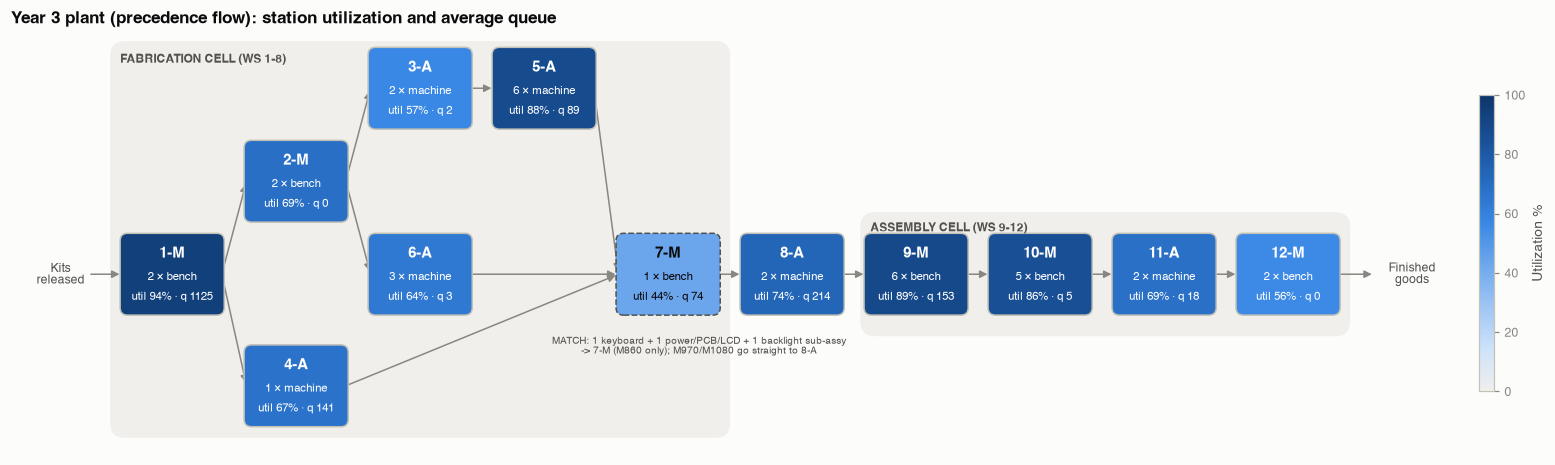

In [3]:
res = run(sc)
print("Sanity checks:", res.checks)
P.plot_block_diagram(res); plt.show()

,Finished,Per week,Demand per week,% of demand,Avg flow time (hr),P90 flow time (hr)
Model,,,,,,
M860,"9,894.000","1,236.750","1,277.540",0.968,30.741,38.202
M970,"8,874.000","1,109.250","1,105.920",1.003,32.132,40.034
M1080,"9,327.000","1,165.875","1,230.320",0.948,31.732,40.416
Total,"28,095.000","3,511.875","3,613.780",0.972,31.509,39.456


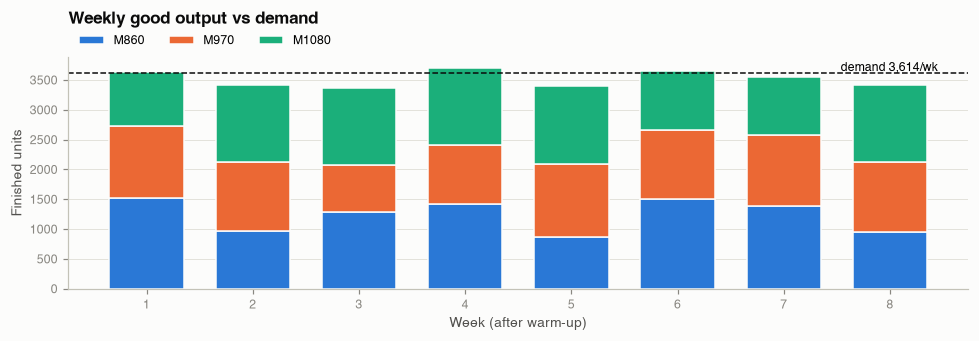

In [4]:
display(res.throughput)
P.plot_throughput(res); plt.show()

### Wave levels: queues at each station
Each bar is one productive day (2 shifts) and shows the **average number of parts waiting** at the station, stacked by model.
- At **1-M** the queue includes the whole lot of kits as it is released.
- Bars that keep growing day after day mean the station can't keep up.
- Each color is one product's lot passing through. The waves show lots arriving, waiting and clearing.

`P.plot_queue_lines(res)` shows the detailed 5-minute view, including how much of the queue is waiting behind the lot gate.

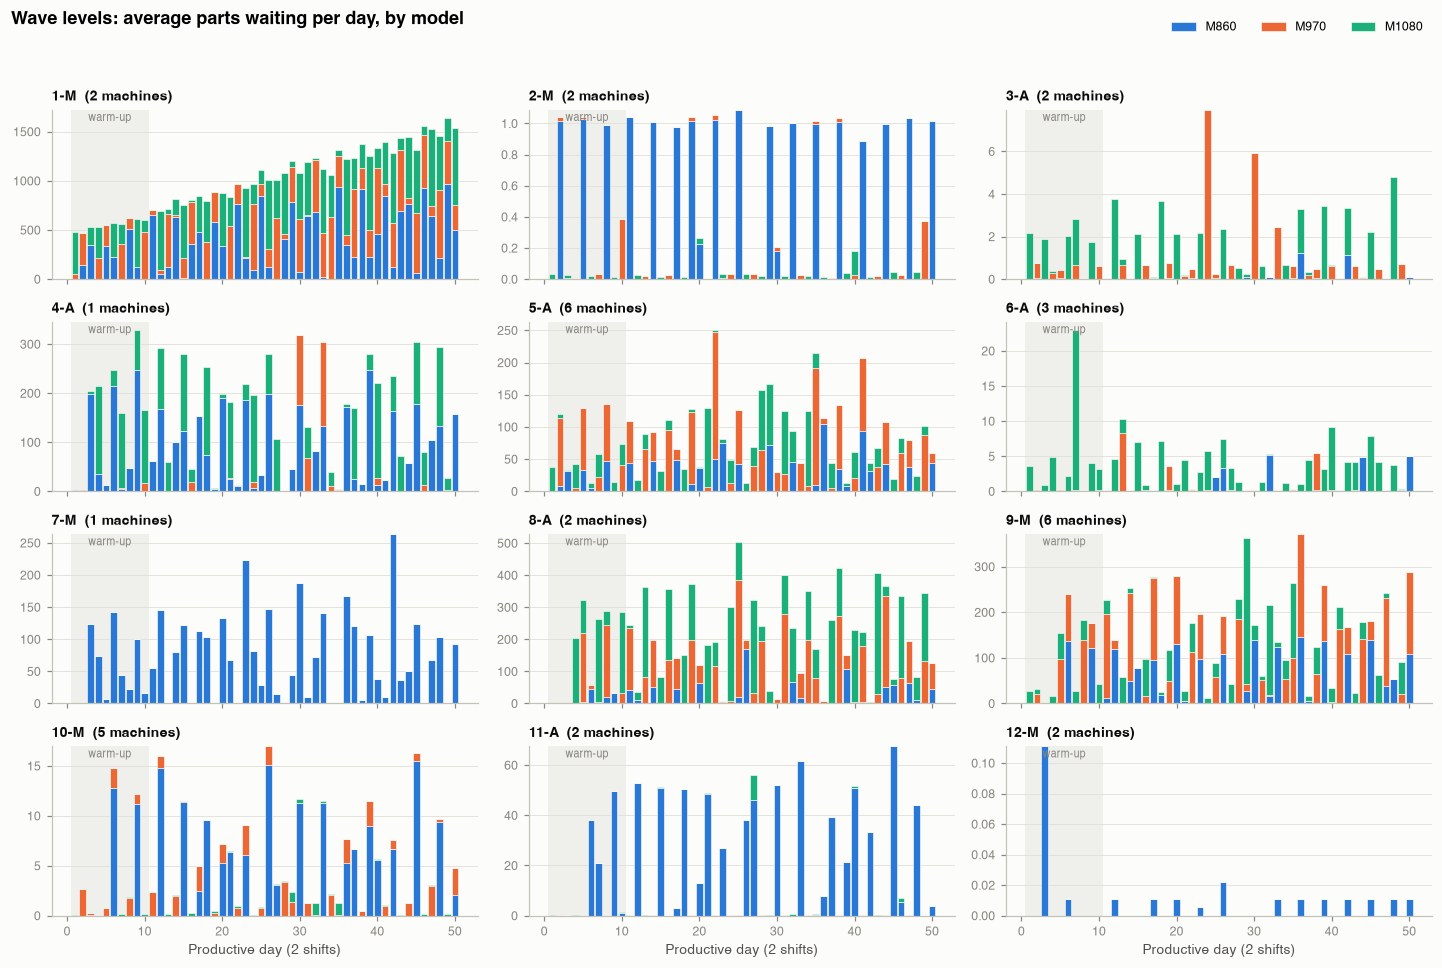

In [5]:
P.plot_wave_levels(res); plt.show()

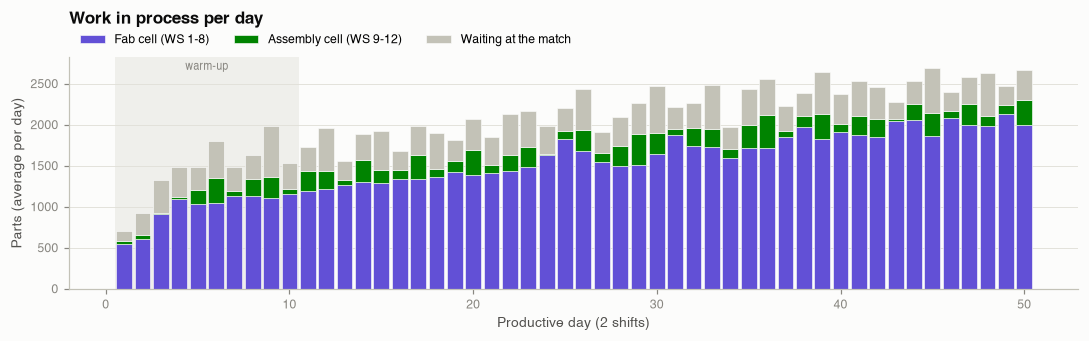

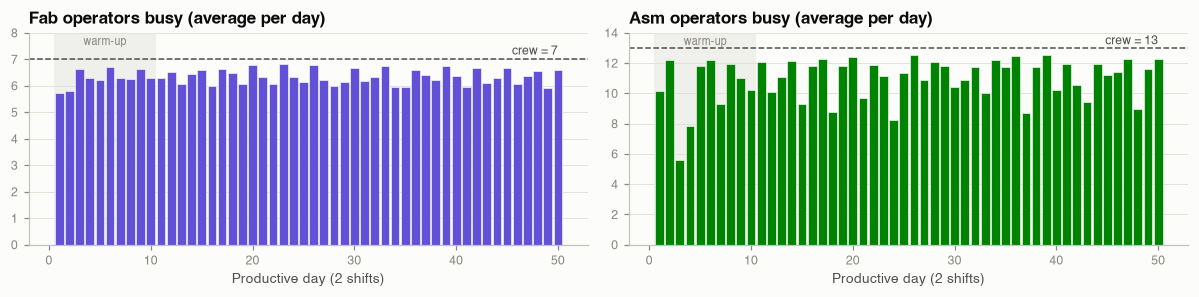

In [6]:
P.plot_wip(res); P.plot_operators_busy(res); plt.show()

## 3. Utilization and capacity of each station and machine

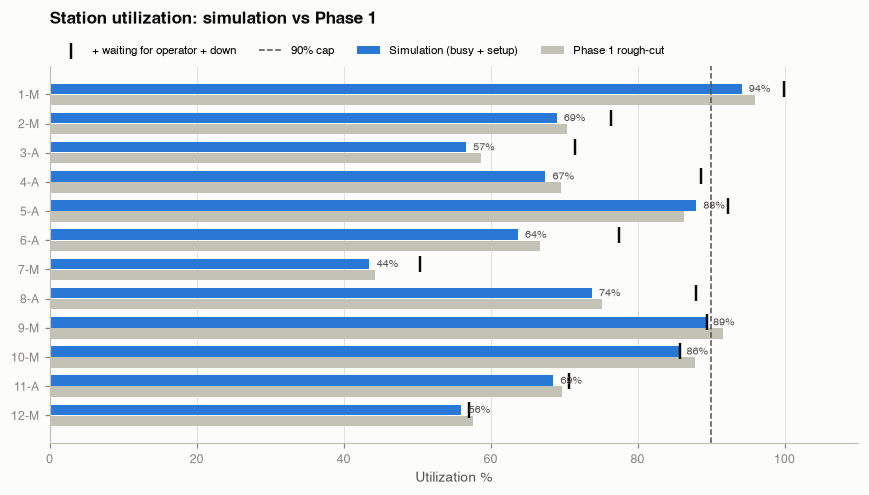

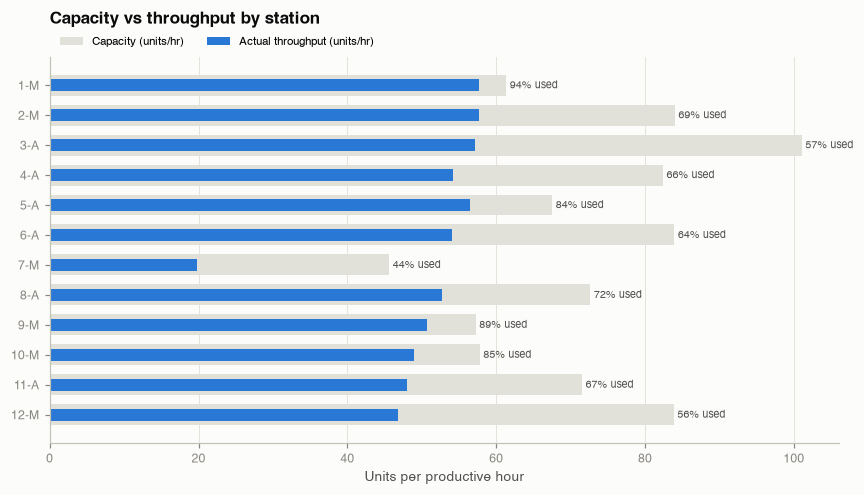

,Cell,Machines,Utilization,Busy %,Setup %,WaitOp %,Down %,Idle %,Capacity (units/hr),Throughput (units/hr),Capacity used %,Spare capacity %,Avg queue,Max queue,Avg wait (min),Wait for operator (min/part)
Station,,,,,,,,,,,,,,,,
1-M,Fab,2,0.942,0.935,0.006,0.058,0.000,0.001,61.332,57.625,0.940,0.060,"1,124.539","2,016.000","1,170.887",0.120
2-M,Fab,2,0.690,0.682,0.008,0.072,0.001,0.237,83.978,57.625,0.686,0.314,0.392,24.000,0.408,0.151
3-A,Fab,2,0.566,0.556,0.010,0.142,0.006,0.285,101.043,57.205,0.566,0.434,1.501,41.000,1.574,0.299
4-A,Fab,1,0.674,0.662,0.012,0.202,0.010,0.113,82.383,54.260,0.659,0.341,140.580,414.000,155.451,0.223
5-A,Fab,6,0.880,0.825,0.055,0.036,0.007,0.077,67.506,56.457,0.836,0.164,88.547,320.000,94.105,0.233
6-A,Fab,3,0.637,0.633,0.004,0.126,0.012,0.225,83.916,53.998,0.643,0.357,3.243,64.000,3.603,0.420
7-M,Fab,1,0.435,0.435,0.000,0.067,0.001,0.497,45.605,19.842,0.435,0.565,73.973,305.000,223.690,0.203
8-A,Fab,2,0.738,0.723,0.015,0.136,0.006,0.120,72.631,52.652,0.725,0.275,213.536,550.000,243.339,0.311
9-M,Asm,6,0.893,0.891,0.002,0.001,0.000,0.106,57.228,50.683,0.886,0.114,153.041,475.000,181.173,0.008


In [7]:
P.plot_utilization(res); P.plot_capacity(res); plt.show()
display(res.stations[["Cell", "Machines", "Utilization", "Busy %", "Setup %", "WaitOp %", "Down %", "Idle %",
                      "Capacity (units/hr)", "Throughput (units/hr)", "Capacity used %", "Spare capacity %",
                      "Avg queue", "Max queue", "Avg wait (min)", "Wait for operator (min/part)"]])

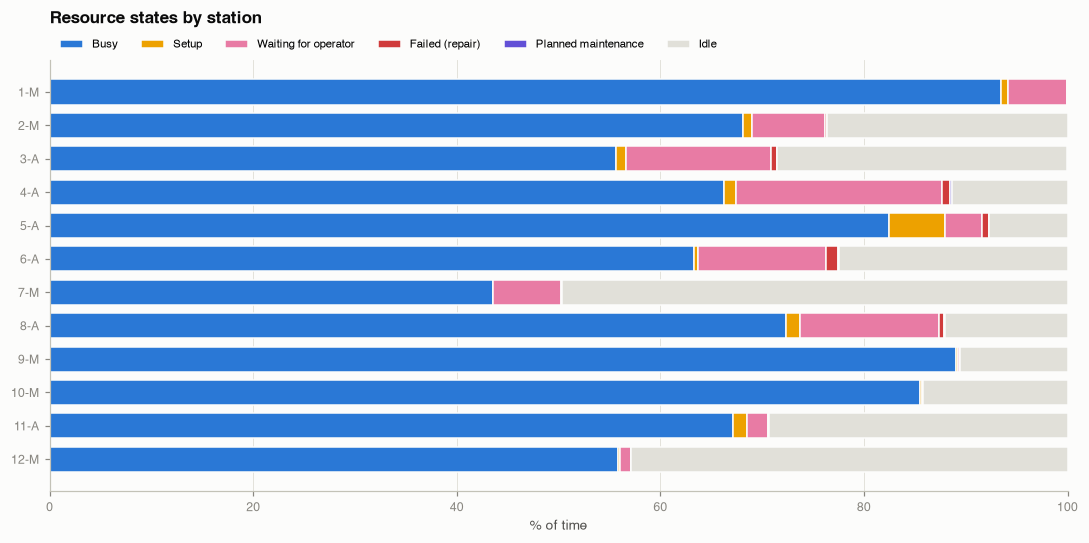

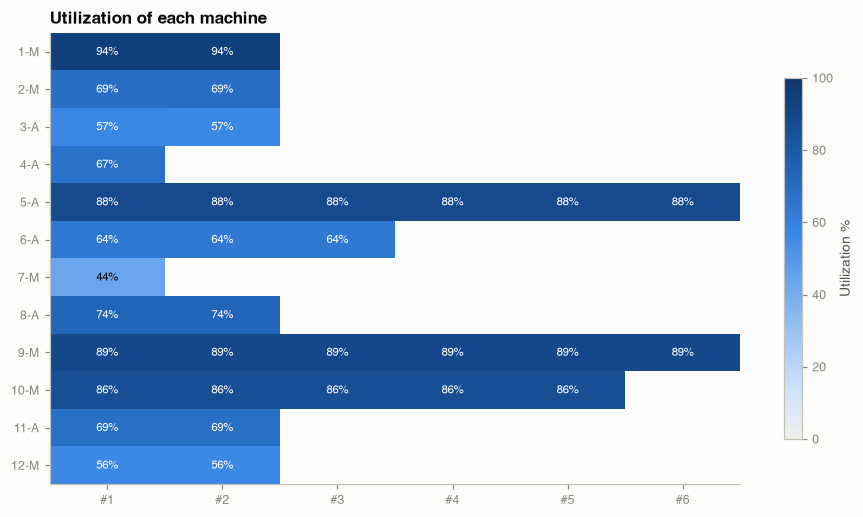

In [8]:
P.plot_machine_states(res, by='station'); P.plot_machine_heatmap(res); plt.show()

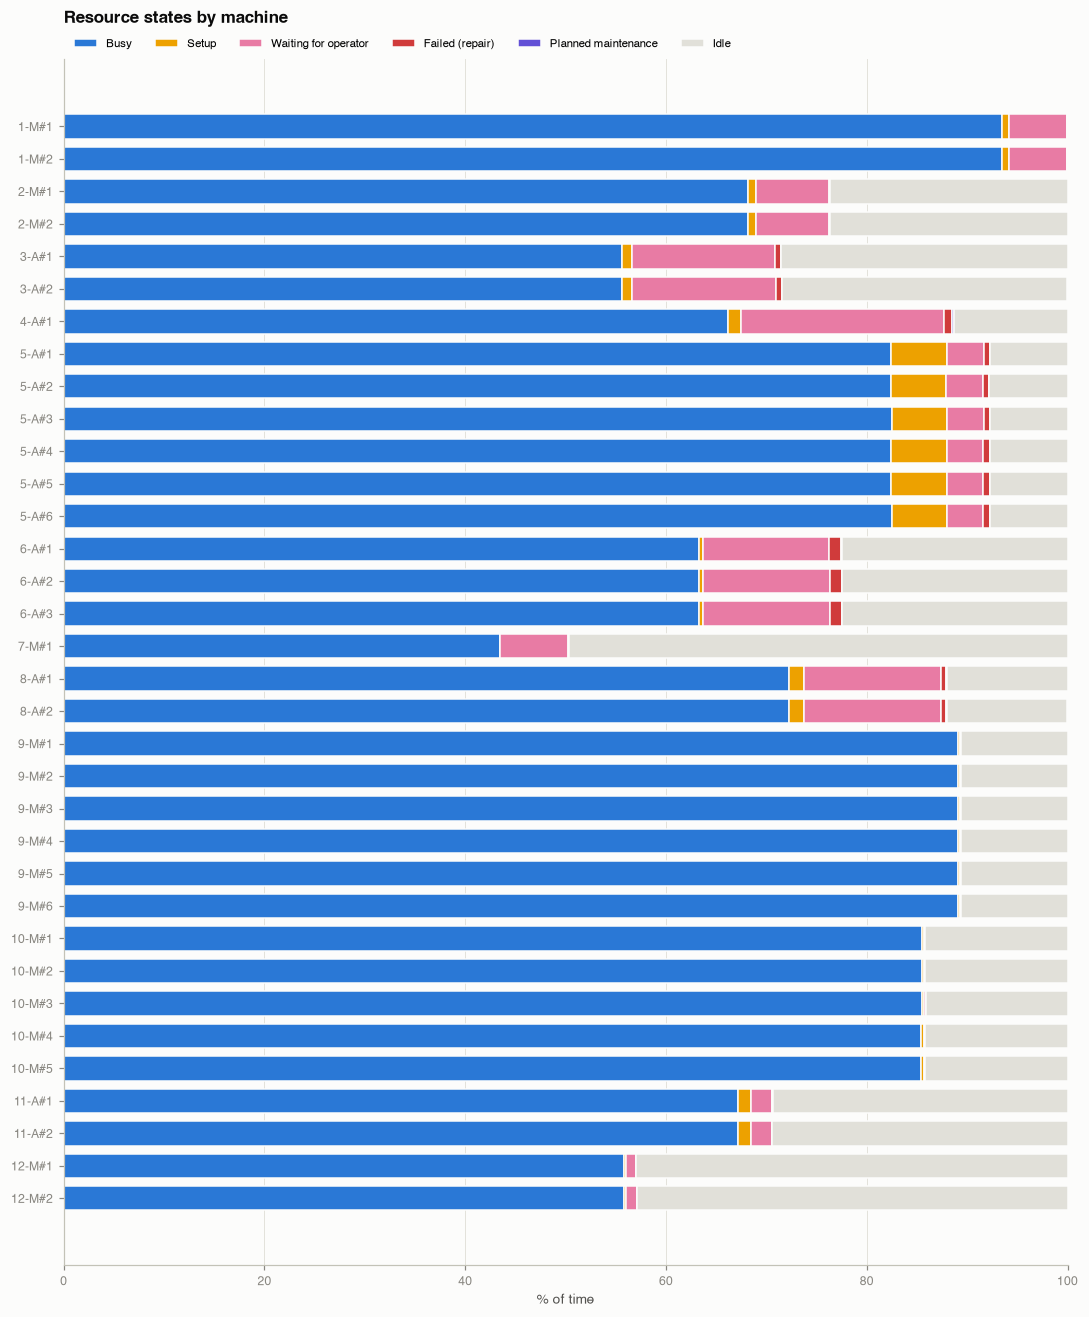

,Station,Busy %,Setup %,WaitOp %,Idle %,Failed %,PM %,Utilization,Units,Setups,Failures,PMs
Machine,,,,,,,,,,,,
1-M#1,1-M,0.935,0.006,0.058,0.001,0.000,0.000,0.942,17288,14,0,0
1-M#2,1-M,0.935,0.006,0.058,0.001,0.000,0.000,0.942,17287,14,0,0
2-M#1,2-M,0.682,0.008,0.072,0.237,0.001,0.000,0.690,17288,14,4,0
2-M#2,2-M,0.682,0.008,0.072,0.237,0.001,0.000,0.690,17287,14,4,0
3-A#1,3-A,0.556,0.010,0.142,0.286,0.006,0.000,0.567,17165,42,7,1
3-A#2,3-A,0.556,0.010,0.143,0.285,0.006,0.000,0.566,17158,42,7,1
4-A#1,4-A,0.662,0.012,0.202,0.113,0.008,0.002,0.674,32556,42,5,3
5-A#1,5-A,0.825,0.055,0.037,0.077,0.007,0.000,0.880,5645,42,2,0
5-A#2,5-A,0.824,0.055,0.036,0.078,0.007,0.000,0.879,5644,42,2,0


In [9]:
P.plot_machine_states(res, by='machine'); plt.show()
display(res.machines)

## 4. Operators: who works where and for how long
Operators are cross-trained within their cell, so any free cell operator takes the next task.
*Waiting for operator* on a machine means the machine was ready but no operator was free.

,Crew per shift,Avg busy,Peak busy,Utilization,Avg WIP in cell,Avg wait for operator (min/part),Avg wait for machine (min/part)
Cell,,,,,,,
Fab,7,6.345,7.000,0.906,"1,662.165",0.247,241.122
Asm,13,11.136,13.000,0.857,188.721,0.024,54.436


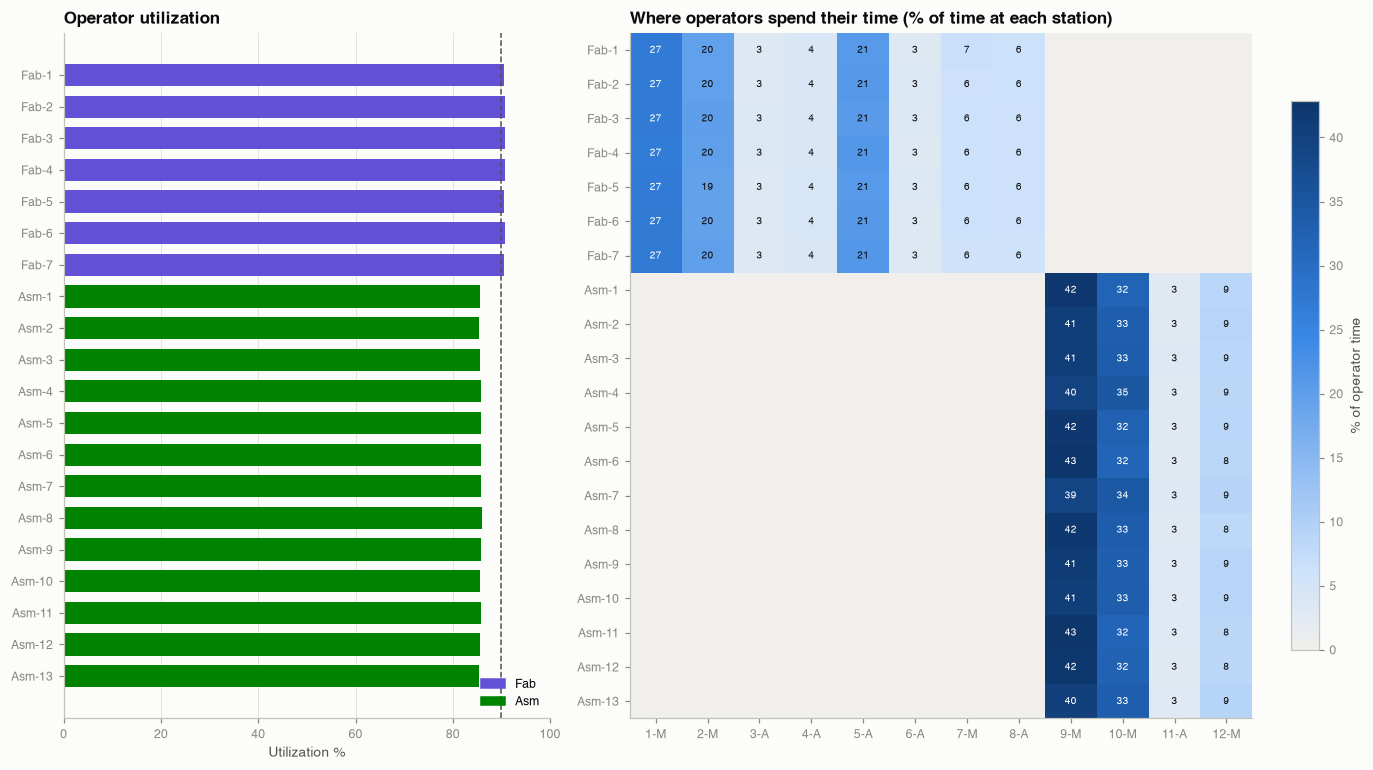

,Cell,Busy (hr),Utilization,Main station,1-M hr,2-M hr,3-A hr,4-A hr,5-A hr,6-A hr,7-M hr,8-A hr,9-M hr,10-M hr,11-A hr,12-M hr
Fab-1,Fab,543.238,0.905,1-M,160.600,118.200,19.300,24.000,124.500,19.700,39.600,37.300,0.000,0.000,0.000,0.000
Fab-2,Fab,543.925,0.907,1-M,161.100,117.600,19.700,24.600,126.400,20.400,36.600,37.600,0.000,0.000,0.000,0.000
Fab-3,Fab,544.036,0.907,1-M,161.400,120.000,20.500,23.600,123.900,20.200,37.800,36.700,0.000,0.000,0.000,0.000
Fab-4,Fab,544.278,0.907,1-M,159.900,118.600,20.100,23.900,128.000,19.800,37.300,36.600,0.000,0.000,0.000,0.000
Fab-5,Fab,543.042,0.905,1-M,161.000,116.900,20.000,25.700,125.100,20.400,37.300,36.600,0.000,0.000,0.000,0.000
Fab-6,Fab,544.885,0.908,1-M,162.800,117.200,19.900,25.100,126.200,19.600,37.800,36.200,0.000,0.000,0.000,0.000
Fab-7,Fab,543.538,0.906,1-M,163.200,119.300,18.800,24.600,128.000,19.000,34.600,36.100,0.000,0.000,0.000,0.000
Asm-1,Asm,513.755,0.856,9-M,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,252.200,192.400,17.000,52.000
Asm-2,Asm,512.605,0.854,9-M,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,243.800,199.000,16.600,53.100
Asm-3,Asm,513.771,0.856,9-M,0.000,0.000,0.000,0.000,0.000,0.000,0.000,0.000,243.100,200.200,18.400,52.100


In [10]:
display(res.cells)
P.plot_operators(res); plt.show()
display(res.operators.join((res.op_station / 60).round(1).add_suffix(" hr")))

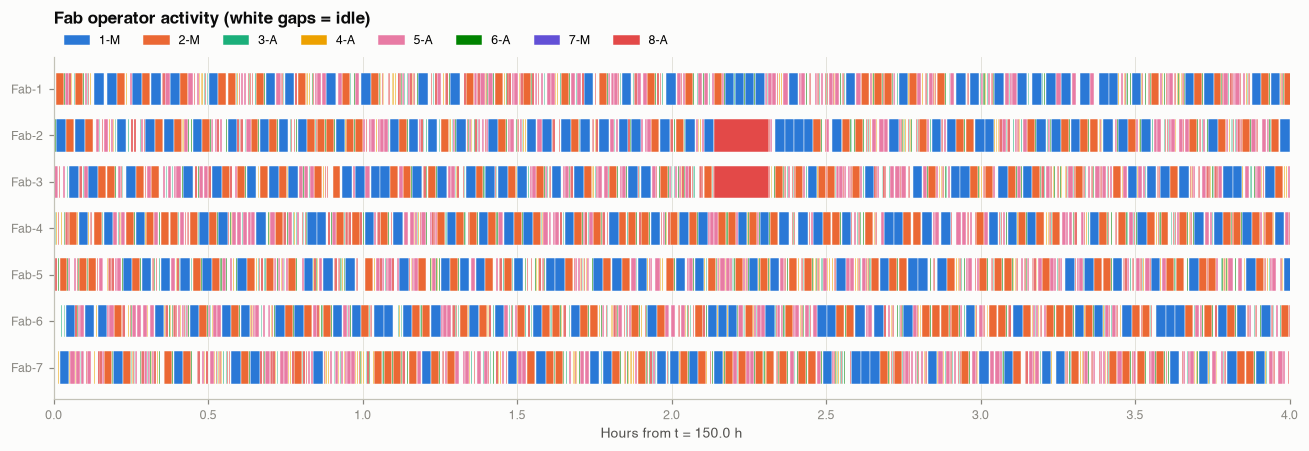

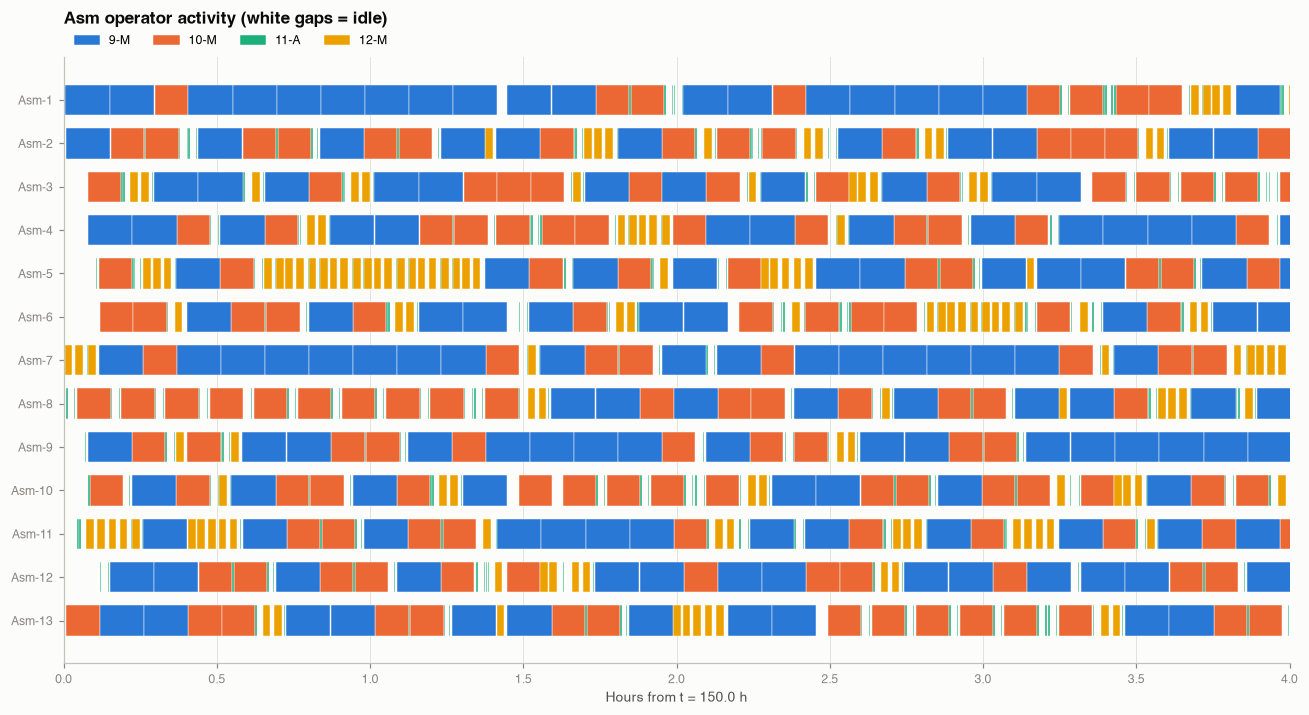

,Operator,Cell,Station,Machine,Task,Lot,Model,Start,End
0,Fab-2,Fab,3-A,3-A#1,load,11,M970,"9,000.257","9,000.353"
1,Fab-4,Fab,6-A,6-A#2,load,11,M970,"9,000.257","9,000.363"
2,Fab-5,Fab,8-A,8-A#2,unload,10,M1080,"9,000.170","9,000.380"
3,Fab-2,Fab,6-A,6-A#1,unload,11,M970,"9,000.353","9,000.458"
4,Fab-4,Fab,3-A,3-A#2,unload,11,M970,"9,000.367","9,000.463"


In [11]:
P.plot_operator_gantt(res, cell="Fab", hours=4); P.plot_operator_gantt(res, cell="Asm", hours=4); plt.show()
res.op_log.head()   # one row per operator task: who, which station/machine, what, when

## 5. Scrap, spare parts and lot completion
Scrap is logged per item: kit, sub-assembly or finished assembly. A scrapped keyboard loses only the keyboard, not the whole unit.

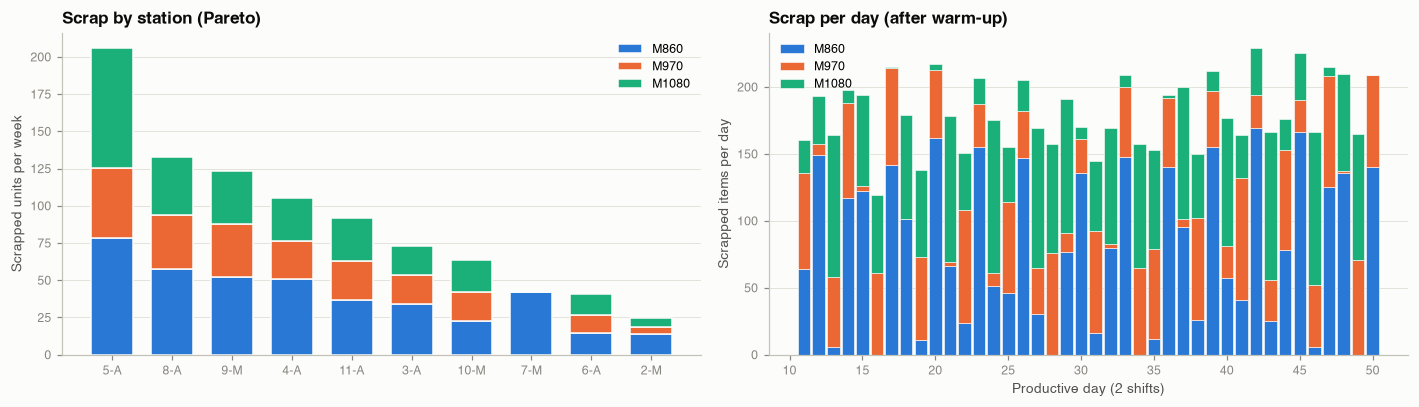

Units per week  Invested_min per week  Labor_dollars per week
Station Item                         Model                                                               
10-M    Display assembly             M1080          21.600                872.200                 176.400
                                     M860           22.900                507.000                 120.100
                                     M970           19.000                645.900                 133.700
11-A    Display assembly             M1080          29.000              1,221.200                 245.300
                                     M860           37.000                882.000                 192.000
                                     M970           25.900                920.400                 188.600
2-M     LCD/PCB set                  M1080           5.800                 22.600                   5.800
                                     M860           13.800                 39.600                  10.200
                                     M970            5.100                 17.400                   4.500
3-A     Power strip/PCB/LCD sub-assy M1080          19.200                108.300                  21.100
                                     M860           33.800                116.100                  26.800
                                     M970           20.000                 96.100                  18.700
4-A     Keyboard sub-assy            M1080          29.200                 86.700                  19.800
                                     M860           51.000                138.300                  28.200
                                     M970           25.100                 58.700                  13.500
5-A     Power strip/PCB/LCD sub-assy M1080          80.200              1,033.200                 125.500
                                     M860           78.200                480.300                  95.800
                                     M970           47.400                533.500                  73.100
6-A     Backlight/sensor sub-assy    M1080          13.600                 98.700                  14.900
                                     M860           14.500                 59.700                  11.500
                                     M970           12.400                 66.400                  11.500
7-M     Display assembly             M860           42.200                603.500                 122.700
8-A     Display assembly             M1080          39.400                990.600                 137.600
                                     M860           57.400                897.000                 175.800
                                     M970           36.100                741.200                 103.900
9-M     Display assembly             M1080          35.800              1,208.400                 218.700
                                     M860           51.900                986.000                 211.000
                                     M970           35.800                993.400                 183.100

,EOQ,Kits,Finished,Finished / EOQ,Short of EOQ,Scrapped,Spare,Unmatched,Yield (finished / kits),Planned yield,Lot flow time (hr)
Model,,,,,,,,,,,
M1080,655.000,785.000,650.778,0.994,6.111,153.944,94.111,10.944,0.829,0.835,37.394
M860,754.000,963.000,754.938,1.001,3.375,237.000,107.062,19.125,0.784,0.783,35.237
M970,596.000,699.000,590.944,0.992,6.333,123.611,59.833,13.389,0.845,0.853,36.349


Spare = components not needed at a Separate; Unmatched = sub-assemblies left at the Match when the lot closed.


In [12]:
P.plot_scrap(res); plt.show()
weeks = res.T / 4500
scr = res.scrap.groupby(["Station", "Item", "Model"]).agg(Units=("Part", "count"), Invested_min=("Invested min", "sum"),
                                                   Labor_dollars=("Labor $", "sum"))
display((scr / weeks).round(1).rename(columns=lambda c: c + " per week"))
lots = res.lots.dropna(subset=["Done"])
display(lots.groupby("Model")[["EOQ", "Kits", "Finished", "Finished / EOQ", "Short of EOQ", "Scrapped", "Spare",
                               "Unmatched", "Yield (finished / kits)", "Planned yield", "Lot flow time (hr)"]].mean())
print("Spare = components not needed at a Separate; Unmatched = sub-assemblies left at the Match when the lot closed.")

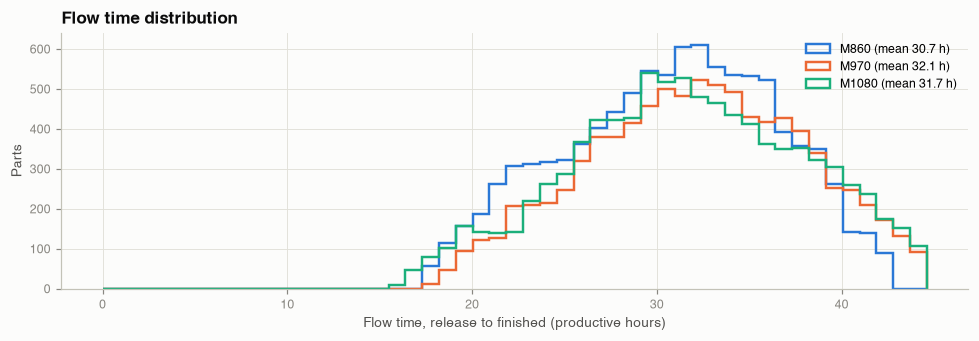

In [13]:
P.plot_flow_time(res); plt.show()

## 6. Replications (Arena Category Overview)
Each replication uses a new random seed for scrap. The table shows the average, the 95% half-width, and the min and max across replications.

In [14]:
reps, summary = run_replications(sc, n=10, n_jobs=N_JOBS)
summary

Average  Half Width   Minimum   Maximum
Category            Statistic                                                                    
Throughput          M860 per week                       1,227.975       3.831 1,220.000 1,236.750
                    M970 per week                       1,113.912       2.390 1,109.250 1,118.000
                    M1080 per week                      1,166.237       3.336 1,158.625 1,172.625
                    Total per week                      3,508.125       5.400 3,498.750 3,521.625
                    % of demand                             0.971       0.001     0.968     0.974
Flow time (hr)      M860                                   30.700       0.048    30.592    30.799
                    M970                                   32.120       0.047    31.999    32.193
                    M1080                                  31.718       0.042    31.579    31.768
WIP                 Average WIP (parts)                 2,214.049       3.561 2,204.053 2,221.142
                    Ending WIP (parts)                  2,869.600      12.400 2,835.000 2,898.000
Operators           Fab utilization                         0.907       0.000     0.906     0.907
                    Fab wait for operator (min/part)        0.246       0.001     0.245     0.247
                    Asm utilization                         0.856       0.001     0.854     0.858
                    Asm wait for operator (min/part)        0.024       0.001     0.023     0.027
Station utilization 1-M                                     0.942       0.000     0.941     0.942
                    2-M                                     0.690       0.000     0.690     0.690
                    3-A                                     0.566       0.000     0.566     0.566
                    4-A                                     0.675       0.000     0.674     0.675
                    5-A                                     0.880       0.000     0.880     0.881
                    6-A                                     0.637       0.000     0.637     0.637
                    7-M                                     0.436       0.000     0.435     0.437
                    8-A                                     0.737       0.001     0.736     0.739
                    9-M                                     0.892       0.001     0.890     0.894
                    10-M                                    0.856       0.001     0.854     0.858
                    11-A                                    0.685       0.001     0.683     0.686
                    12-M                                    0.560       0.001     0.558     0.562
Avg queue           1-M                                 1,119.813       3.454 1,110.761 1,124.539
                    2-M                                     0.392       0.002     0.386     0.395
                    3-A                                     1.498       0.019     1.443     1.547
                    4-A                                   139.488       0.948   136.274   140.759
                    5-A                                    89.694       0.518    88.547    90.941
                    6-A                                     3.101       0.097     2.953     3.358
                    7-M                                    75.489       0.670    73.973    77.154
                    8-A                                   215.765       1.592   211.908   219.967
                    9-M                                   152.647       0.986   150.545   154.935
                    10-M                                    5.079       0.096     4.907     5.355
                    11-A                                   18.082       0.220    17.623    18.530
                    12-M                                    0.004       0.000     0.003     0.004
Down %              1-M                                     0.000       0.000     0.000     0.000
                    2-M                 

## 7. Bottlenecks: are they where Phase 1 expected?
Phase 1 (Table 2.3.1) ranked stations by rough-cut utilization and flagged **9-M and 10-M** as the bottlenecks.
The simulation adds what the spreadsheet can't capture:
- queueing,
- time machines lose waiting for a shared operator,
- setups at every lot changeover,
- the lot gate,
- failures and PM.

In [15]:
bn = res.bottlenecks()
display(bn)
avg_util = summary.xs("Station utilization").Average.rename("Avg util (10 reps)")
avg_q = summary.xs("Avg queue").Average.rename("Avg queue (10 reps)")
display(pd.concat([avg_util, avg_q], axis=1).join(bn[["Phase 1 util"]]).sort_values("Avg util (10 reps)", ascending=False))

,Machines,Utilization,Phase 1 util,Avg queue,Avg wait (min),Gate-blocked %,Wait for operator (min/part),Down %,Spare capacity %,Sim rank,Phase 1 rank
Station,,,,,,,,,,,
1-M,2,0.942,0.960,"1,124.539","1,170.887",0.001,0.120,0.000,0.060,1,1
9-M,6,0.893,0.916,153.041,181.173,0.005,0.008,0.000,0.114,2,2
5-A,6,0.880,0.864,88.547,94.105,0.005,0.233,0.007,0.164,3,4
10-M,5,0.857,0.878,5.077,6.217,0.001,0.010,0.000,0.152,4,3
8-A,2,0.738,0.751,213.536,243.339,0.087,0.311,0.006,0.275,5,5
2-M,2,0.690,0.704,0.392,0.408,0.000,0.151,0.001,0.314,6,6
11-A,2,0.685,0.697,18.390,22.964,0.000,0.051,0.001,0.328,7,7
4-A,1,0.674,0.695,140.580,155.451,0.000,0.223,0.010,0.341,8,8
6-A,3,0.637,0.667,3.243,3.603,0.000,0.420,0.012,0.357,9,9


,Avg util (10 reps),Avg queue (10 reps),Phase 1 util
Statistic,,,
1-M,0.942,"1,119.813",0.960
9-M,0.892,152.647,0.916
5-A,0.880,89.694,0.864
10-M,0.856,5.079,0.878
8-A,0.737,215.765,0.751
2-M,0.690,0.392,0.704
11-A,0.685,18.082,0.697
4-A,0.675,139.488,0.695
6-A,0.637,3.101,0.667


## 8. Validation against Phase 1
- **(a)** With failures and PM off and Phase 1's convention of one setup per lot per station (`setup_scope="station"`), station utilization should reproduce the Phase 1 table. Check it in Year 3, where the plan has capacity to spare.
- **(b)** Each lot should deliver about EOQ good units (sending EOQ × scrap factor through each branch).
- **(c)** Accounting checks must hold.

In [16]:
v = run(get_scenario(3, failures_on=False, pm_on=False, setup_scope="station", run_weeks=20, keep_logs=False))
cmp = pd.DataFrame({"Sim util + down": v.stations.Utilization + v.stations["Down %"], "Phase 1": v.stations["Phase 1 util"]})
cmp["Diff (pts)"] = (cmp.iloc[:, 0] - cmp.iloc[:, 1]) * 100
display(cmp)
assert cmp["Diff (pts)"].abs().max() < 5, "Year 3 utilization differs from Phase 1 by > 5 pts"
assert v.throughput.loc["Total", "% of demand"] > 0.97
assert all(val == 0 for key, val in v.checks.items() if "must be 0" in key), v.checks
ly = res.lots.dropna(subset=["Done"]).groupby("Model")[["EOQ", "Finished", "Finished / EOQ", "Yield (finished / kits)", "Planned yield"]].mean()
display(ly)
assert (ly["Finished / EOQ"] - 1).abs().max() < 0.03
print("Validation passed")

,Sim util + down,Phase 1,Diff (pts)
Station,,,
1-M,0.961,0.960,0.177
2-M,0.703,0.704,-0.042
3-A,0.580,0.587,-0.689
4-A,0.692,0.695,-0.331
5-A,0.859,0.864,-0.476
6-A,0.655,0.667,-1.178
7-M,0.443,0.442,0.106
8-A,0.747,0.751,-0.424
9-M,0.912,0.916,-0.435


,EOQ,Finished,Finished / EOQ,Yield (finished / kits),Planned yield
Model,,,,,
M1080,655.000,650.778,0.994,0.829,0.835
M860,754.000,754.938,1.001,0.784,0.783
M970,596.000,590.944,0.992,0.845,0.853


Validation passed


## 9. Setup policy: every machine vs one setup per lot
In the base model **every machine** at a station pays the setup when it starts a new lot. At 5-A that is up to 6 × 65 min, and each setup also ties up a Fab operator.
Phase 1 costed **one setup per lot per station**. This compares the two, plus giving 1-M (the busiest manual bench) first call on Fab operators.

Scenario,Every machine sets up (base),One setup per lot (Phase 1),Base + 1-M operator priority
KPI,,,
Throughput|Total per week,3.51e+03 ± 7.6,3.61e+03 ± 8.3,3.6e+03 ± 13
Throughput|% of demand,0.97 ± 0.0021,0.998 ± 0.0023,0.997 ± 0.0035
WIP|Average WIP (parts),2.21e+03 ± 6.4,1.44e+03 ± 2.5,2.01e+03 ± 7.9
WIP|Ending WIP (parts),2.87e+03 ± 23,1.22e+03 ± 30,1.65e+03 ± 44
Flow time (hr)|M860,30.7 ± 0.071,18.6 ± 0.04,24.9 ± 0.13
Flow time (hr)|M970,32.1 ± 0.086,19.7 ± 0.039,25.8 ± 0.13
Flow time (hr)|M1080,31.7 ± 0.083,18.9 ± 0.053,25.2 ± 0.15
Operators|Fab utilization,0.907 ± 0.00037,0.882 ± 0.00013,0.928 ± 0.00013
Operators|Asm utilization,0.856 ± 0.0013,0.871 ± 0.00071,0.872 ± 0.0013


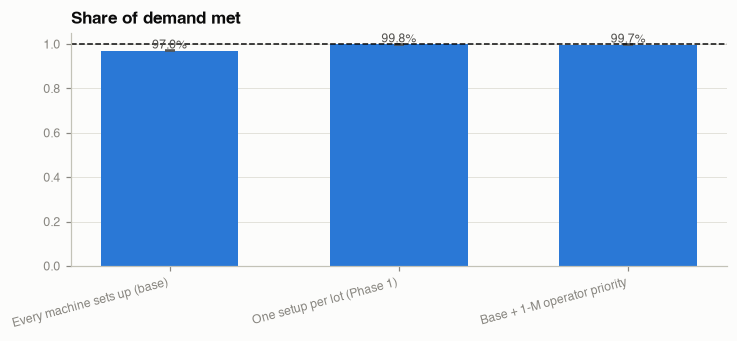

In [17]:
long_s, wide_s = X.compare({
    "Every machine sets up (base)": get_scenario(YEAR),
    "One setup per lot (Phase 1)": get_scenario(YEAR, setup_scope="station"),
    "Base + 1-M operator priority": get_scenario(YEAR, op_priority={"1-M": -1}),
}, n=5, n_jobs=N_JOBS)
display(wide_s.loc[X.KEY_KPIS])
P.plot_compare(long_s, "Throughput|% of demand", "Share of demand met", fmt="{:.1%}", ref=1.0); plt.show()

## 10. Maintenance and failures
- PM is every N units (PM frequency).
- Breakdowns are every MTBF × 60 / (average minutes per part) units.
- TQM cuts downtime by 75%.

Scenario,No failures / PM,PM only,Failures + PM (base),TQM (-75% downtime)
KPI,,,,
Throughput|Total per week,3.51e+03 ± 11,3.51e+03 ± 8.8,3.51e+03 ± 7.6,3.51e+03 ± 15
Throughput|% of demand,0.97 ± 0.0031,0.972 ± 0.0024,0.97 ± 0.0021,0.973 ± 0.0041
WIP|Average WIP (parts),2.17e+03 ± 8,2.17e+03 ± 7.6,2.21e+03 ± 6.4,2.18e+03 ± 12
WIP|Ending WIP (parts),2.82e+03 ± 27,2.82e+03 ± 27,2.87e+03 ± 23,2.84e+03 ± 42
Flow time (hr)|M860,30 ± 0.068,30 ± 0.11,30.7 ± 0.071,30.2 ± 0.22
Flow time (hr)|M970,31.5 ± 0.081,31.5 ± 0.11,32.1 ± 0.086,31.6 ± 0.21
Flow time (hr)|M1080,31.1 ± 0.11,31.1 ± 0.14,31.7 ± 0.083,31.2 ± 0.22
Operators|Fab utilization,0.908 ± 0.00021,0.907 ± 0.00038,0.907 ± 0.00037,0.907 ± 0.00042
Operators|Asm utilization,0.856 ± 0.0015,0.857 ± 0.0014,0.856 ± 0.0013,0.857 ± 0.0024


Scenario,No failures / PM,PM only,Failures + PM (base),TQM (-75% downtime)
KPI,,,,
Down %|1-M,0 ± 0,0 ± 0,0 ± 0,0 ± 0
Down %|2-M,0 ± 0,0 ± 0,0.00111 ± 0,0.000278 ± 0
Down %|3-A,0 ± 0,0.000278 ± 0,0.00611 ± 0,0.00153 ± 0
Down %|4-A,0 ± 0,0.00167 ± 3e-19,0.01 ± 0,0.0025 ± 0
Down %|5-A,0 ± 0,0 ± 0,0.00667 ± 1.2e-18,0.00167 ± 3e-19
Down %|6-A,0 ± 0,0.000556 ± 0,0.0122 ± 0,0.00306 ± 0
Down %|7-M,0 ± 0,0 ± 0,0.00125 ± 0,0.000313 ± 0
Down %|8-A,0 ± 0,0.000833 ± 1.5e-19,0.00583 ± 0,0.00146 ± 0
Down %|9-M,0 ± 0,0 ± 0,0 ± 0,0 ± 0


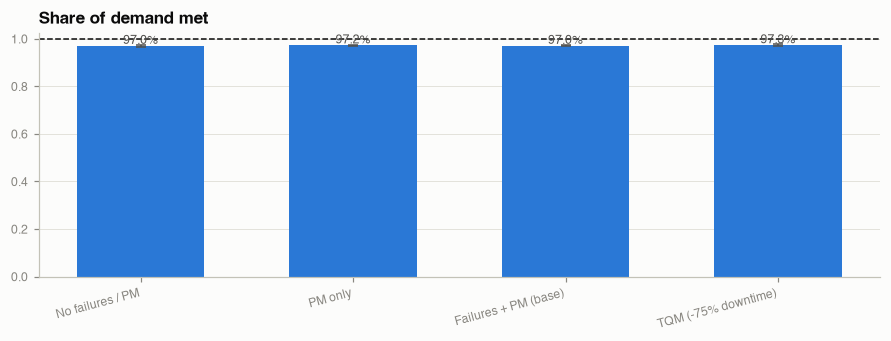

In [18]:
long_m, wide_m = X.maintenance_study(YEAR, n=5, n_jobs=N_JOBS)
display(wide_m.loc[X.KEY_KPIS])
display(wide_m.loc[[k for k in wide_m.index if k.startswith("Down %")]])
P.plot_compare(long_m, "Throughput|% of demand", "Share of demand met", fmt="{:.1%}", ref=1.0); plt.show()

## 11. Do we need more operators?
The sweep adds or removes operators per shift in each cell, keeping the other cell at plan.
Watch throughput, WIP, and *wait for operator*.

Scenario,Fab 6 (-1),Fab 7 (+0),Fab 8 (+1),Fab 9 (+2)
KPI,,,,
Throughput|Total per week,3.06e+03 ± 17,3.51e+03 ± 7.6,3.61e+03 ± 12,3.61e+03 ± 7.4
Throughput|% of demand,0.846 ± 0.0047,0.97 ± 0.0021,0.998 ± 0.0033,0.999 ± 0.0021
WIP|Average WIP (parts),9.25e+03 ± 1.6e+02,2.21e+03 ± 6.4,1.51e+03 ± 4.4,1.4e+03 ± 4.1
WIP|Ending WIP (parts),1.35e+04 ± 3.8e+02,2.87e+03 ± 23,1.34e+03 ± 15,1.34e+03 ± 25
Flow time (hr)|M860,84.2 ± 0.94,30.7 ± 0.071,20.9 ± 0.019,19.4 ± 0.092
Flow time (hr)|M970,88.5 ± 0.33,32.1 ± 0.086,21.8 ± 0.051,20.3 ± 0.059
Flow time (hr)|M1080,87.5 ± 0.95,31.7 ± 0.083,21.1 ± 0.076,19.5 ± 0.054
Operators|Fab utilization,0.983 ± 0.00012,0.907 ± 0.00037,0.814 ± 0.00019,0.724 ± 0.00024
Operators|Asm utilization,0.749 ± 0.0042,0.856 ± 0.0013,0.874 ± 0.0014,0.874 ± 0.0016


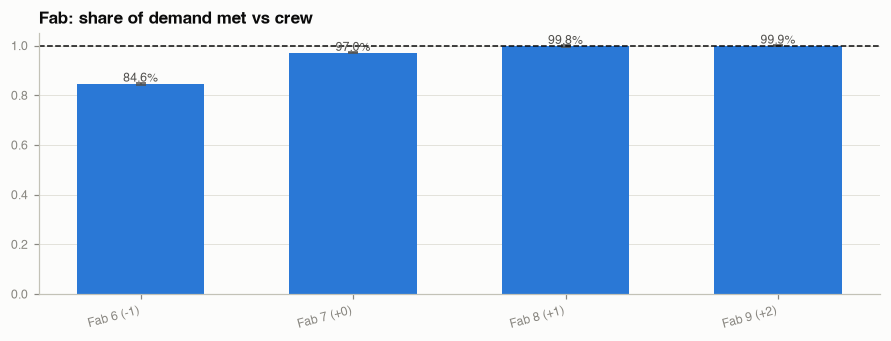

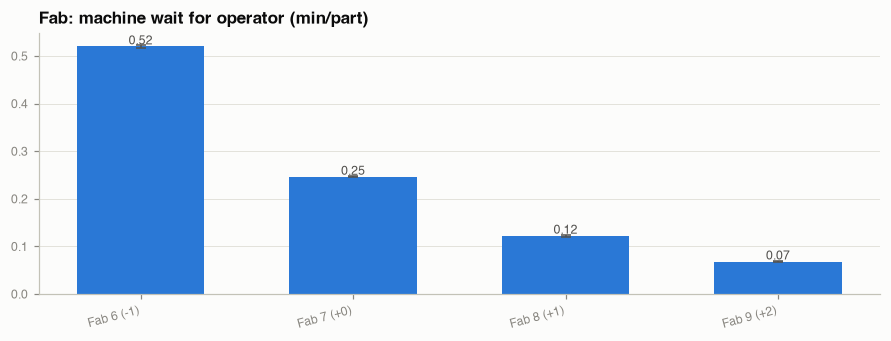

Scenario,Asm 12 (-1),Asm 13 (+0),Asm 14 (+1),Asm 15 (+2)
KPI,,,,
Throughput|Total per week,3.5e+03 ± 8.8,3.51e+03 ± 7.6,3.51e+03 ± 14,3.5e+03 ± 6
Throughput|% of demand,0.969 ± 0.0024,0.97 ± 0.0021,0.97 ± 0.004,0.969 ± 0.0017
WIP|Average WIP (parts),2.25e+03 ± 9.3,2.21e+03 ± 6.4,2.21e+03 ± 12,2.2e+03 ± 5.6
WIP|Ending WIP (parts),2.91e+03 ± 27,2.87e+03 ± 23,2.84e+03 ± 37,2.84e+03 ± 30
Flow time (hr)|M860,31.9 ± 0.16,30.7 ± 0.071,30.5 ± 0.16,30.5 ± 0.083
Flow time (hr)|M970,32.5 ± 0.17,32.1 ± 0.086,32.1 ± 0.14,32.1 ± 0.13
Flow time (hr)|M1080,32.1 ± 0.13,31.7 ± 0.083,31.7 ± 0.13,31.6 ± 0.12
Operators|Fab utilization,0.907 ± 0.00031,0.907 ± 0.00037,0.906 ± 0.00038,0.907 ± 0.00021
Operators|Asm utilization,0.926 ± 0.0022,0.856 ± 0.0013,0.794 ± 0.0018,0.741 ± 0.00053


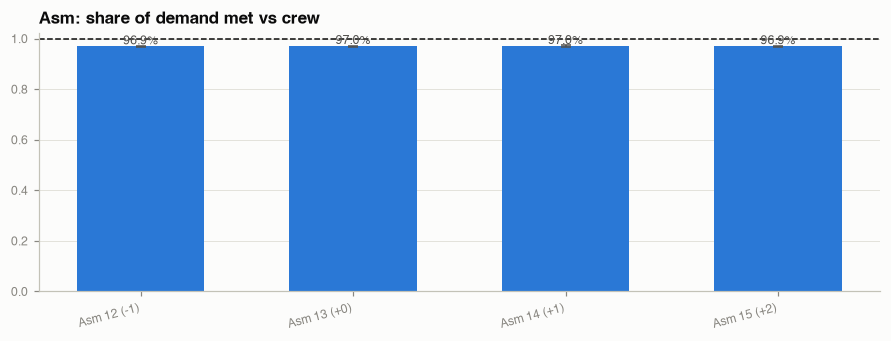

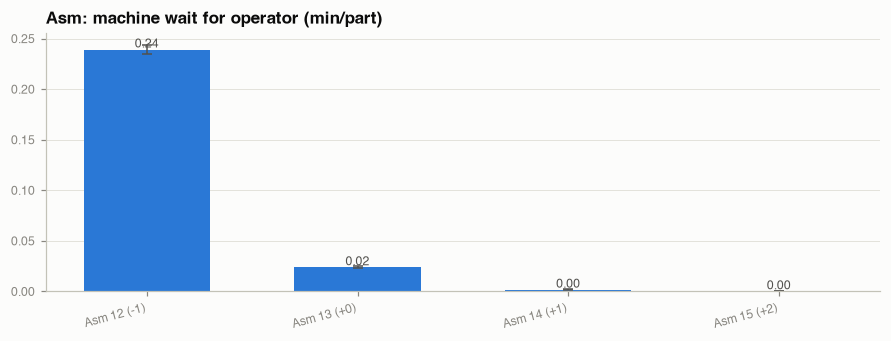

In [19]:
for cell in ["Fab", "Asm"]:
    long_o, wide_o = X.operator_sweep(YEAR, cell=cell, deltas=(-1, 0, 1, 2), n=5, n_jobs=N_JOBS)
    display(wide_o.loc[X.KEY_KPIS])
    P.plot_compare(long_o, "Throughput|% of demand", f"{cell}: share of demand met vs crew", fmt="{:.1%}", ref=1.0)
    P.plot_compare(long_o, f"Operators|{cell} wait for operator (min/part)", f"{cell}: machine wait for operator (min/part)", fmt="{:.2f}")
    plt.show()

## 12. Capacity what-ifs
- Phase 1 recommended one more bench at 9-M and at 10-M.
- The other options test the stations the simulation flags.
- Edit `extra` to try anything else.

Scenario,Plan,+1 bench 9-M & 10-M,+1 bench 1-M,"+1 bench 1-M, +1 Fab op"
KPI,,,,
Throughput|Total per week,3.51e+03 ± 7.6,3.5e+03 ± 10,3.19e+03 ± 4.9,3.61e+03 ± 8.8
Throughput|% of demand,0.97 ± 0.0021,0.967 ± 0.0028,0.881 ± 0.0014,1 ± 0.0024
WIP|Average WIP (parts),2.21e+03 ± 6.4,2.29e+03 ± 17,1.05e+04 ± 79,1.96e+03 ± 4
WIP|Ending WIP (parts),2.87e+03 ± 23,2.94e+03 ± 27,1.65e+04 ± 1.5e+02,1.87e+03 ± 16
Flow time (hr)|M860,30.7 ± 0.071,32 ± 0.23,69.8 ± 0.52,21.7 ± 0.058
Flow time (hr)|M970,32.1 ± 0.086,34.4 ± 0.33,71.2 ± 0.4,22.6 ± 0.052
Flow time (hr)|M1080,31.7 ± 0.083,33.3 ± 0.38,70.5 ± 0.37,21.9 ± 0.021
Operators|Fab utilization,0.907 ± 0.00037,0.907 ± 0.00041,0.912 ± 0.00027,0.817 ± 0.00013
Operators|Asm utilization,0.856 ± 0.0013,0.858 ± 0.0008,0.775 ± 0.00077,0.874 ± 0.0013


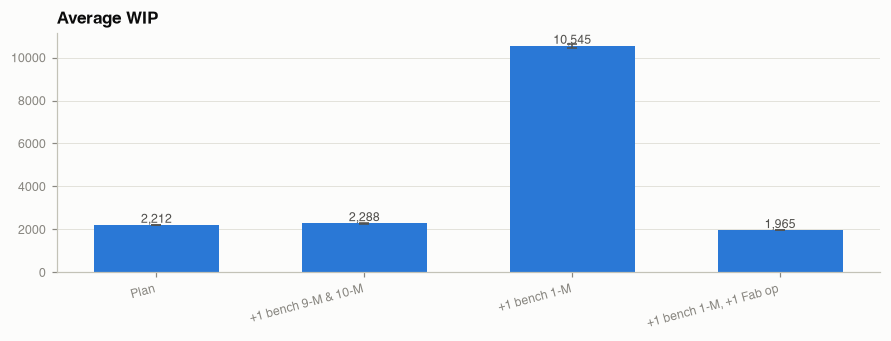

In [20]:
from lcd_sim.params import MACHINES
m = MACHINES[YEAR]
long_c, wide_c = X.capacity_whatif(YEAR, n=5, n_jobs=N_JOBS, extra={
    "+1 bench 1-M": {"machines": {"1-M": m["1-M"] + 1}},
    "+1 bench 1-M, +1 Fab op": {"machines": {"1-M": m["1-M"] + 1}, "operators": {"Fab": sc.operators["Fab"] + 1}},
})
display(wide_c.loc[X.KEY_KPIS])
P.plot_compare(long_c, "WIP|Average WIP (parts)", "Average WIP", fmt="{:,.0f}"); plt.show()

## 13. Years 1-3 side by side (Phase 1 plan for each year)

In [21]:
long_y, wide_y = X.years_compare(n=5, n_jobs=N_JOBS)
display(wide_y.loc[X.KEY_KPIS])
display(wide_y.loc[[k for k in wide_y.index if k.startswith("Station utilization")]])

Scenario,Year 1,Year 2,Year 3
KPI,,,
Throughput|Total per week,2.3e+03 ± 9.2,2.55e+03 ± 10,3.51e+03 ± 7.6
Throughput|% of demand,0.935 ± 0.0037,0.857 ± 0.0034,0.97 ± 0.0021
WIP|Average WIP (parts),3.27e+03 ± 28,9.91e+03 ± 45,2.21e+03 ± 6.4
WIP|Ending WIP (parts),4.36e+03 ± 80,1.57e+04 ± 67,2.87e+03 ± 23
Flow time (hr)|M860,48 ± 0.38,77.9 ± 0.28,30.7 ± 0.071
Flow time (hr)|M970,46.1 ± 0.33,76.5 ± 0.48,32.1 ± 0.086
Flow time (hr)|M1080,46.3 ± 0.28,77.4 ± 0.4,31.7 ± 0.083
Operators|Fab utilization,0.854 ± 0.001,0.851 ± 0.00027,0.907 ± 0.00037
Operators|Asm utilization,0.805 ± 0.0036,0.719 ± 0.002,0.856 ± 0.0013


Scenario,Year 1,Year 2,Year 3
KPI,,,
Station utilization|1-M,0.672 ± 6.9e-17,0.807 ± 6.4e-05,0.942 ± 0.00021
Station utilization|2-M,0.913 ± 0.0021,0.59 ± 4.7e-05,0.69 ± 0.00013
Station utilization|3-A,0.737 ± 0.002,0.806 ± 0.00042,0.566 ± 0.00019
Station utilization|4-A,0.492 ± 2.1e-15,0.588 ± 4.9e-05,0.675 ± 0.00026
Station utilization|5-A,0.851 ± 0.0023,0.753 ± 0.00099,0.88 ± 0.00046
Station utilization|6-A,0.63 ± 0.0018,0.807 ± 0.00022,0.637 ± 0.00016
Station utilization|7-M,0.312 ± 0.001,0.354 ± 0.0008,0.436 ± 0.0011
Station utilization|8-A,0.487 ± 0.0015,0.532 ± 0.00082,0.737 ± 0.00081
Station utilization|9-M,0.868 ± 0.0034,0.756 ± 0.0016,0.892 ± 0.0013
